In [322]:
# Import Libraries
import pandas as pd
import sklearn as skl
import imblearn as imb
import seaborn as sb
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import mlxtend as mlx

from pathlib import Path

In [324]:
#DATA LOADING AND CLEANING

In [326]:
# Inflation Data
inflation = pd.read_csv("inflation_data.csv")

# Inflation Adjustment
base_year = 2026
base_amount = inflation.loc[inflation["year"] == base_year, "amount"].iloc[0]
inflation["factor"] = base_amount / inflation["amount"]

inflation.head

<bound method NDFrame.head of     year  amount  inflation rate    factor
0   2000    1.00            0.03  1.960000
1   2001    1.03            0.03  1.902913
2   2002    1.04            0.02  1.884615
3   2003    1.07            0.02  1.831776
4   2004    1.10            0.03  1.781818
5   2005    1.13            0.03  1.734513
6   2006    1.17            0.03  1.675214
7   2007    1.20            0.03  1.633333
8   2008    1.25            0.04  1.568000
9   2009    1.25           -0.00  1.568000
10  2010    1.27            0.02  1.543307
11  2011    1.31            0.03  1.496183
12  2012    1.33            0.02  1.473684
13  2013    1.35            0.01  1.451852
14  2014    1.37            0.02  1.430657
15  2015    1.38            0.00  1.420290
16  2016    1.39            0.01  1.410072
17  2017    1.42            0.02  1.380282
18  2018    1.46            0.02  1.342466
19  2019    1.48            0.02  1.324324
20  2020    1.50            0.01  1.306667
21  2021    1.57        

In [328]:
# FEC data 
folder = Path(r"COSC5610_Data")

# Storage
dfs = {}
frames = []

# Columns
columns = ["CAND_ID", "CAND_NAME", "CAND_INC_STAT", "PRTY_CODE", "CAND_PTY_AFFIL", "TTL_RECEIPTS", "TRANS_FROM_AUTH_COMTE", "TTL_DISB", "TRANS_TO_AUTH_COMTE", "STRT_CASH", "END_CASH", "CAND_CONTRIB", "CAND_LOANS", "OTHER_LOANS", "CAND_LOAN_REPAY", "OTHER_LOAN_REPAY", "DEBTS_OWED_BY", "TTL_INDIV_CONTRIB", "CAND_OFFICE_STATE", "CAND_OFFICE_DISTRICT", "SPEC_ELEC_STAT", "PRIM_ELEC_STAT", "RUN_ELEC_STATUS", "GEN_ELECTION", "GEN_ELEC_PRECENT", "OTHER_POL_CMTE_CONTRIB", "POL_PRTY_CONTRIB", "CVRG_END_DT", "INDIV_REFUNDS", "CMTE_REFUNDS"]
money_cols = ["TTL_RECEIPTS", "TRANS_FROM_AUTH_COMTE", "TTL_DISB", "TRANS_TO_AUTH_COMTE", "STRT_CASH", "END_CASH", "CAND_CONTRIB", "CAND_LOANS", "OTHER_LOANS", "CAND_LOAN_REPAY", "OTHER_LOAN_REPAY", "DEBTS_OWED_BY", "TTL_INDIV_CONTRIB", "OTHER_POL_CMTE_CONTRIB", "POL_PRTY_CONTRIB", "INDIV_REFUNDS", "CMTE_REFUNDS"]

drop_columns = ["SPEC_ELEC_STAT", "PRIM_ELEC_STAT", "RUN_ELEC_STATUS", "GEN_ELECTION", "GEN_ELEC_PRECENT"] # Only filled in 2004 and 2006 data set, need to outsource election data


# Starting Year
year = 2004 

# Create Dataframes
for file in sorted(folder.glob("*.txt")): 
    df = pd.read_csv(file, sep="|", header=None, names=columns)
    df["YEAR"] = year
    dfs[f"df{year}"] = df
    frames.append(df)
    year += 2

# Print name and shape of each data frame
for name, df in dfs.items():
    print(name, df.shape)

df2004 (1578, 31)
df2006 (1631, 31)
df2008 (1769, 31)
df2010 (2364, 31)
df2012 (2197, 31)
df2014 (1841, 31)
df2016 (1897, 31)
df2018 (2676, 31)
df2020 (2637, 31)
df2022 (2854, 31)
df2024 (2378, 31)
df2026 (3026, 31)


In [330]:
# Combine data for cleaning
combined = pd.concat(frames, ignore_index=True)

# Drop irrelevant rows
combined = combined.drop(columns = drop_columns)

# Drop irrelevant columns (Presidential candidates)
combined = combined[~combined["CAND_ID"].str.startswith("P")].copy()

combined.shape

(25241, 26)

In [332]:
combined.info()

<class 'pandas.DataFrame'>
Index: 25241 entries, 0 to 26847
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CAND_ID                 25241 non-null  str    
 1   CAND_NAME               25241 non-null  str    
 2   CAND_INC_STAT           25216 non-null  str    
 3   PRTY_CODE               25241 non-null  int64  
 4   CAND_PTY_AFFIL          25229 non-null  str    
 5   TTL_RECEIPTS            25241 non-null  float64
 6   TRANS_FROM_AUTH_COMTE   25241 non-null  float64
 7   TTL_DISB                25241 non-null  float64
 8   TRANS_TO_AUTH_COMTE     25241 non-null  float64
 9   STRT_CASH               25241 non-null  float64
 10  END_CASH                25241 non-null  float64
 11  CAND_CONTRIB            25241 non-null  float64
 12  CAND_LOANS              25241 non-null  float64
 13  OTHER_LOANS             25241 non-null  float64
 14  CAND_LOAN_REPAY         25241 non-null  float64
 15  O

In [334]:
null_cols = combined.columns[combined.isna().any()].tolist()
print(null_cols)

['CAND_INC_STAT', 'CAND_PTY_AFFIL', 'CAND_OFFICE_DISTRICT']


In [336]:
for col in null_cols:
    print(col, "| Number of Nan values: ", combined[col].isna().sum(), "\n", combined[col].unique())

CAND_INC_STAT | Number of Nan values:  25 
 <ArrowStringArray>
['C', 'I', 'O', nan]
Length: 4, dtype: str
CAND_PTY_AFFIL | Number of Nan values:  12 
 <ArrowStringArray>
['DEM', 'REP', 'IND', 'GRE', 'LIB', 'UNK', 'CST',  'TX', 'DFL', 'OTH', 'SWP',
 'NPA', 'Rep', 'NPP', 'NNE', 'CON', 'Dem', 'PAF', 'REF', 'UNI', 'FRE', 'PRO',
   nan, 'TLP', 'JCN', 'CRV', 'AIP',   'W', 'IDP', 'CIT', 'SUS', 'IAP', 'WFP',
 'LPF',  'IP', 'NON',  'UN', 'PPT', 'GOP', 'NOP', 'SEP', 'AMP', 'REC', 'MTP',
   'C', 'UPA', 'PPY', 'SAM', 'VET', 'LBU', 'ICD',  'AL',   'R', 'PFP', '(I)',
 'AKI',  'MO', 'PNP', 'UUP',  '08',  'PG', 'AIC', 'FWD',  'DE']
Length: 64, dtype: str
CAND_OFFICE_DISTRICT | Number of Nan values:  55 
 [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49. 50. 51. 52. 53.
 nan 66.]


In [338]:
# Investigate Party Affiliation
missing_party = combined[combined["CAND_PTY_AFFIL"].isna()]
print(missing_party[["YEAR", "CAND_ID", "CAND_NAME", "PRTY_CODE", "CAND_INC_STAT", "CAND_PTY_AFFIL"]])

       YEAR    CAND_ID                      CAND_NAME  PRTY_CODE  \
2926   2006  H6WV01061           MORAN, DAVID DUNSTAN          3   
3262   2008  H8AZ01120             MAUPIN, BRENT GEER          3   
3811   2008  H8LA06030               JACKSON, MICHAEL          3   
4282   2008  H8OH15092            ECKHART, DON ELIJAH          3   
6428   2010  H0OR00014     KELLER, DOUGLAS FITZGERALD          3   
7462   2012  H2CA02167               CLARKE, BROOKE J          3   
7544   2012  H2CA24161        BOUTTE, MATTHEW ELLIOTT          3   
7557   2012  H2CA26091                   PARKS, LINDA          3   
12379  2016  H6NY13170  FENSTERMAKER, SCOTT LLOYD MR.          3   
15875  2018  S8OH00144            FARIS, STEPHEN I MR          3   
22839  2024  H4OR03242                     MEYER, JOE          3   
26595  2026  S6IL00698         SCHWARTZBERG, STEVEN J          3   

      CAND_INC_STAT CAND_PTY_AFFIL  
2926              C            NaN  
3262              O            NaN  
3811

In [340]:
# Resolve Candidates with confirmed parties based on research (13)
party_fix = {
    ("H6WV01061", 2006): "W",
    ("H8AZ01120", 2008): "IND",
    ("H8LA06030", 2008): "IND",
    ("H8OH15092", 2008): "IND",
    ("H0OR00014", 2010): "REP",
    ("H2CA02167", 2012): "NOP",
    ("H2CA26091", 2012): "NOP",
    ("H2CA24161", 2012): "NOP",
    ("H6NY13170", 2016): "IND",
    ("S8OH00144", 2018): "IND",
    ("P40008716", 2022): "OTH",
    ("H4OR03242", 2024): "PG",
    ("S6IL00698", 2026): "IND",
}
def fix_party(df):
    for (cid, yr), party in party_fix.items():
        m = (df["CAND_ID"] == cid) & (df["YEAR"] == yr) & df["CAND_PTY_AFFIL"].isna()
        df.loc[m, "CAND_PTY_AFFIL"] = party
    df["CAND_PTY_AFFIL"] = df["CAND_PTY_AFFIL"].fillna("UNRESOLVED")

# Fix combined df
fix_party(combined)

# Fix individual dfs
for df in dfs.values():
    fix_party(df)

In [341]:
# Resolve District discrepancies based on research (68)
district_fix = {
    ("H2AZ09092", 2012): 9,    # Stapley, AZ-9
    ("H2TX00106", 2012): 30,   # Morenoff, TX-30
    ("H4MA03089", 2014): 3,    # Imholt, MA-3
    ("H4MS00013", 2014): 3,    # Magee, MS-3 
    ("H4OK05082", 2014): 5,    # Rainwater, OK-5 
    ("H6AK00235", 2016): 0,    # Lindbeck, Alaska at-large
    ("H6AS00031", 2016): 0,    # Hunkin-Finau, American Samoa at-large
    ("H4DE00078", 2024): 0,    # Whalen, Delaware at-large
    ("H6GU00059", 2026): 0,    # Torres, Guam at-large
    ("H6MD03508", 2026): 3,    # Dyches, MD-3
}

def fix_district(df):
    na = df["CAND_OFFICE_DISTRICT"].isna()

    # Senate and president have no district. FEC defaults to 0
    sp = df["CAND_ID"].str[0].isin(["S", "P"])
    df.loc[na & sp, "CAND_OFFICE_DISTRICT"] = 0

    # House candidates from research
    for (cid, yr), dist in district_fix.items():
        m = (df["CAND_ID"] == cid) & (df["YEAR"] == yr) & df["CAND_OFFICE_DISTRICT"].isna()
        df.loc[m, "CAND_OFFICE_DISTRICT"] = dist

# Fix combined df
fix_district(combined)

# Fix individual dfs
for df in dfs.values():
    fix_district(df)

In [342]:
# Resolve incumbency status discrepancies
combined['CAND_INC_STAT'] = combined['CAND_INC_STAT'].fillna('UNK')

In [370]:
# Add a flag for office type
combined["OFFICE"] = combined["CAND_ID"].str[0].map({"H": "HOUSE", "S": "SENATE"})

In [372]:
# Inflation Rows
adj_combined = combined
# Look up each row's factor by its YEAR
adj_combined["factor"] = adj_combined["YEAR"].map(inflation.set_index("year")["factor"])

# Create an _ADJ column for every monetary column at once
adj_cols = [f"ADJ_{c}" for c in money_cols]
adj_combined[adj_cols] = adj_combined[money_cols].mul(adj_combined["factor"], axis=0)

adj_combined.info()

<class 'pandas.DataFrame'>
Index: 25241 entries, 0 to 26847
Data columns (total 45 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   CAND_ID                     25241 non-null  str    
 1   CAND_NAME                   25241 non-null  str    
 2   CAND_INC_STAT               25241 non-null  str    
 3   PRTY_CODE                   25241 non-null  int64  
 4   CAND_PTY_AFFIL              25241 non-null  str    
 5   TTL_RECEIPTS                25241 non-null  float64
 6   TRANS_FROM_AUTH_COMTE       25241 non-null  float64
 7   TTL_DISB                    25241 non-null  float64
 8   TRANS_TO_AUTH_COMTE         25241 non-null  float64
 9   STRT_CASH                   25241 non-null  float64
 10  END_CASH                    25241 non-null  float64
 11  CAND_CONTRIB                25241 non-null  float64
 12  CAND_LOANS                  25241 non-null  float64
 13  OTHER_LOANS                 25241 non-null  flo

In [350]:
# DATA EXPLORATION

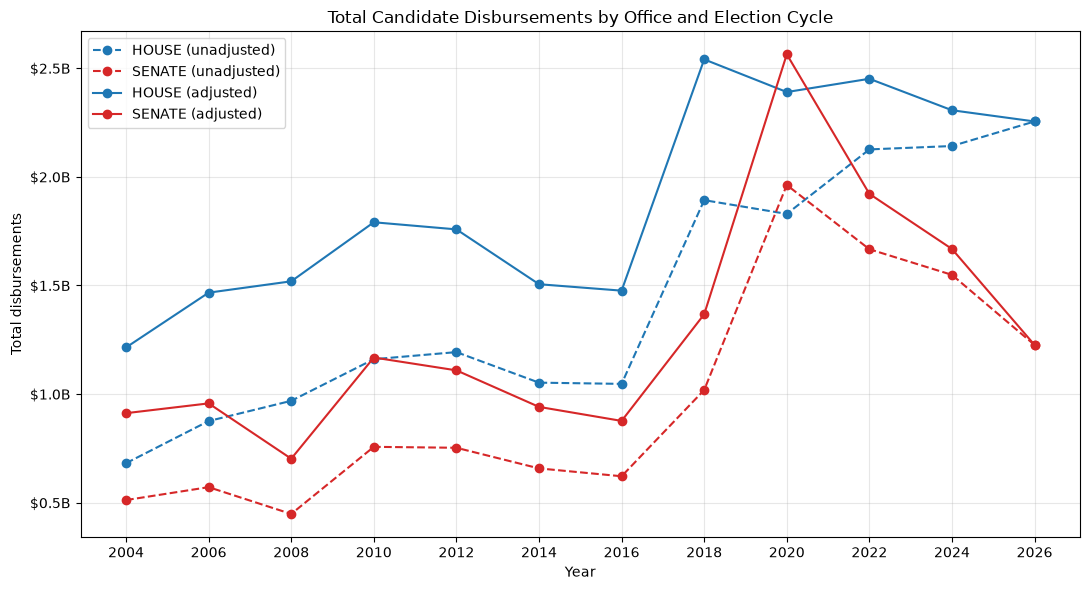

In [382]:
yearly = (combined.groupby(["YEAR", "OFFICE"])[["TTL_DISB", "ADJ_TTL_DISB"]]
          .sum()
          .unstack("OFFICE"))

# Turn the (measure, office) column pairs into legend labels, e.g. "House (adjusted)"
yearly.columns = yearly.columns.map(
    lambda t: f"{t[1]} ({'adjusted' if t[0].startswith('ADJ_') else 'unadjusted'})"
)

fig, ax = plt.subplots(figsize=(11, 6))
yearly.plot(
    ax=ax,
    style=["o--", "o--", "o-", "o-"],
    color=["tab:blue", "tab:red", "tab:blue", "tab:red"],
)

ax.set_title("Total Candidate Disbursements by Office and Election Cycle")
ax.set_xlabel("Year")
ax.set_ylabel("Total disbursements")
ax.set_xticks(yearly.index)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x/1e9:.1f}B"))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()